In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sqlalchemy import create_engine

In [ ]:
server = 'localhost\\SQLEXPRESS'

database = 'Sales_DataWareHouse'

Connection_url = f"mssql+pyodbc://@{server}/{database}?driver=ODBC+Driver+17+for+SQL+server&Trusted_Connection=Yes"
try:
    engine = create_engine(Connection_url)
    print("Connection successful! Engine is ready.")
except Exception as e:
    print(f"Error in connection {e}")

Connection successful! Engine is ready.


In [ ]:
db_tables = ['gold.dim_customer','gold.dim_product','gold.dim_orders','gold.fact_sales']
df = {}

for i in db_tables:
    query = f'SELECT * FROM {i}'
    data = pd.read_sql(query,con=engine)
    df[i] = data


In [ ]:

print('=' * 100)
print('*'*39 +' Data Quality Report ' + '*'*40)
print('=' * 100)

for i in db_tables:
    print('=' * 38 + f' {i} ' + '='*38)
    print(f'{df[i].shape[0]} Rows & {df[i].shape[1]} Columns.')
    print('+'*50)
    duplicated = df[i].duplicated().sum()
    print(f'{duplicated} rows are duplicate.')
    print('-'*50)
    print(f'{df[i].info()}')
    print('-' * 50)
    print('-' * 38 + 'Statistical Analysis' + '-'*38)
    print(df[i].describe().T)
    print('-' * 50)
    missing_summary={
    "Missing Count": df[i].isna().sum(),
    "Missing Percentage" :df[i].isnull().mean() * 100
    }
    print('-' * 38 + 'Missing Analysis' + '-'*38)
    print(f'Missing Count:\n{missing_summary["Missing Count"]}\n\nMissing Percentage:\n{missing_summary["Missing Percentage"]}')
    print('-' * 50)
    print(f'Numbers of Unique Fields in {i}:\n{df[i].nunique()}')
    print('-' * 50)

    print('\n\n')

*************************************** Data Quality Report ****************************************
====================================== gold.dim_customer ======================================
40000 Rows & 16 Columns.
++++++++++++++++++++++++++++++++++++++++++++++++++
0 rows are duplicate.
--------------------------------------------------
<class 'pandas.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 16 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   customer_id          40000 non-null  str    
 1   customer_first_name  40000 non-null  str    
 2   customer_last_name   40000 non-null  str    
 3   gender               40000 non-null  str    
 4   age                  40000 non-null  int64  
 5   age_group            40000 non-null  str    
 6   dob                  40000 non-null  object 
 7   email                40000 non-null  str    
 8   phone                40000 non-null  str    
 9   c

# Fixing Datatype

In [ ]:
df['gold.dim_customer']['dob'] = pd.to_datetime(df['gold.dim_customer']['dob'])
df['gold.dim_customer']['registration_date'] = pd.to_datetime(df['gold.dim_customer']['registration_date'])

df['gold.dim_orders']['order_date'] = pd.to_datetime(df['gold.dim_orders']['order_date'])
df['gold.dim_orders']['delivery_date'] = pd.to_datetime(df['gold.dim_orders']['delivery_date'])

In [ ]:
customer_df = df['gold.dim_customer']
product_df = df['gold.dim_product']
orders_df = df['gold.dim_orders']
sales_df = df['gold.fact_sales']

# Univariate Analysis

# Categorical

# Customer Table

### Gender

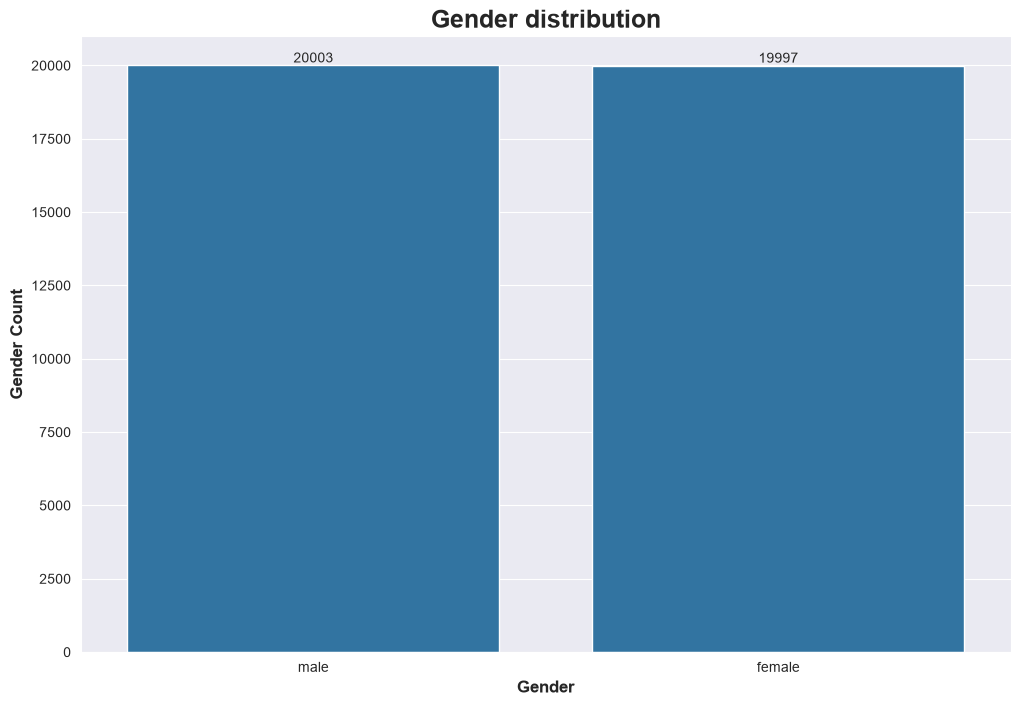

In [ ]:
plt.figure(figsize=(12,8))
sns.set_style('darkgrid')

ax =sns.countplot(data = customer_df, x = 'gender')

for container in ax.containers:
    ax.bar_label(container)

ax.set_title('Gender distribution', weight = 'bold', size = 18)
plt.xlabel('Gender', weight = 'bold', fontsize = 12)
plt.ylabel('Gender Count', weight = 'bold', fontsize = 12)

plt.show()

### Both Male and Female Gender Distributed are equally

### Age /Age Group

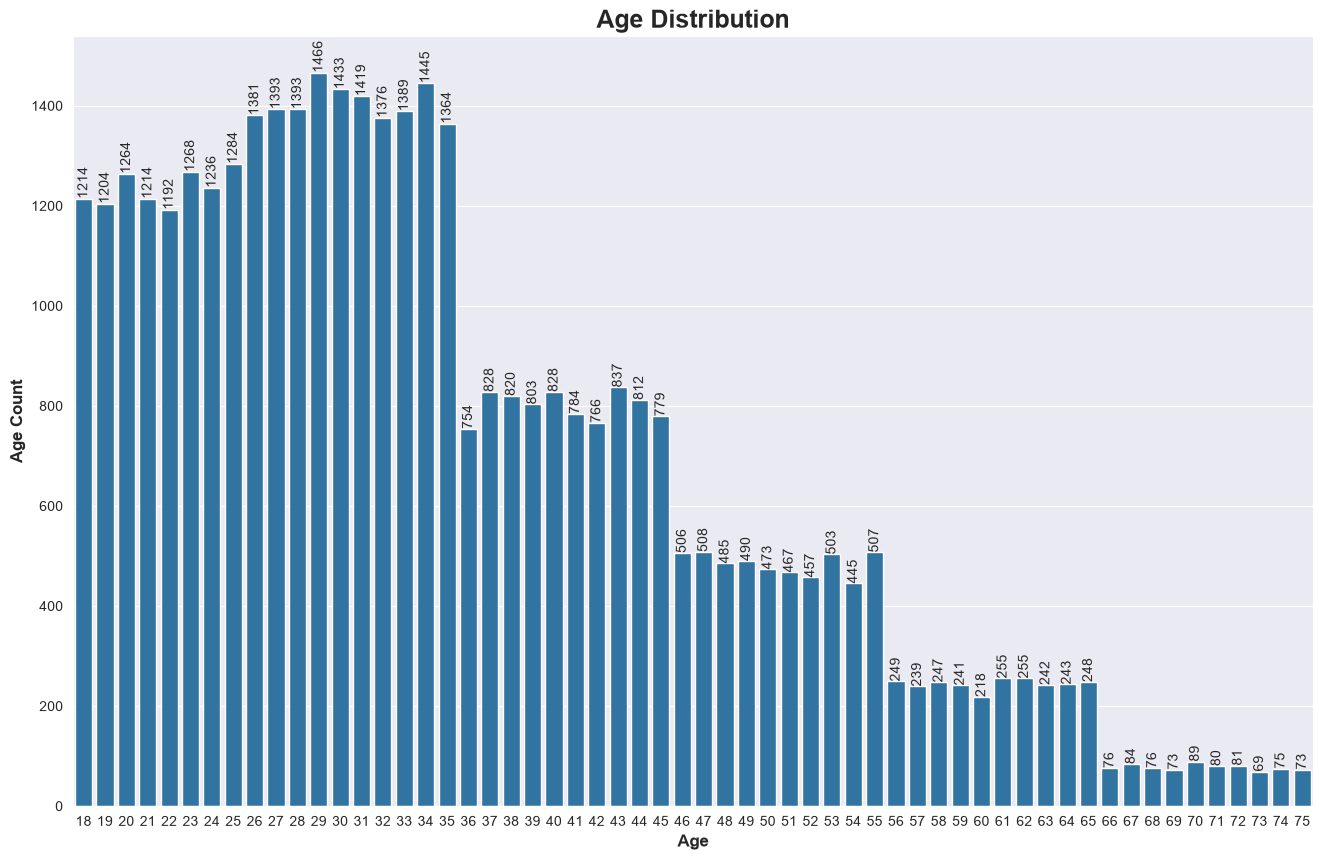

In [ ]:
plt.figure(figsize=(16,10))
sns.set_style('darkgrid')

ax =sns.countplot(data = customer_df, x = 'age')

for container in ax.containers:
    ax.bar_label(container, rotation = 90)

ax.set_title('Age Distribution', weight = 'bold', size = 18)
plt.xlabel('Age', weight = 'bold', fontsize = 12)
plt.ylabel('Age Count', weight = 'bold', fontsize = 12)

plt.show()

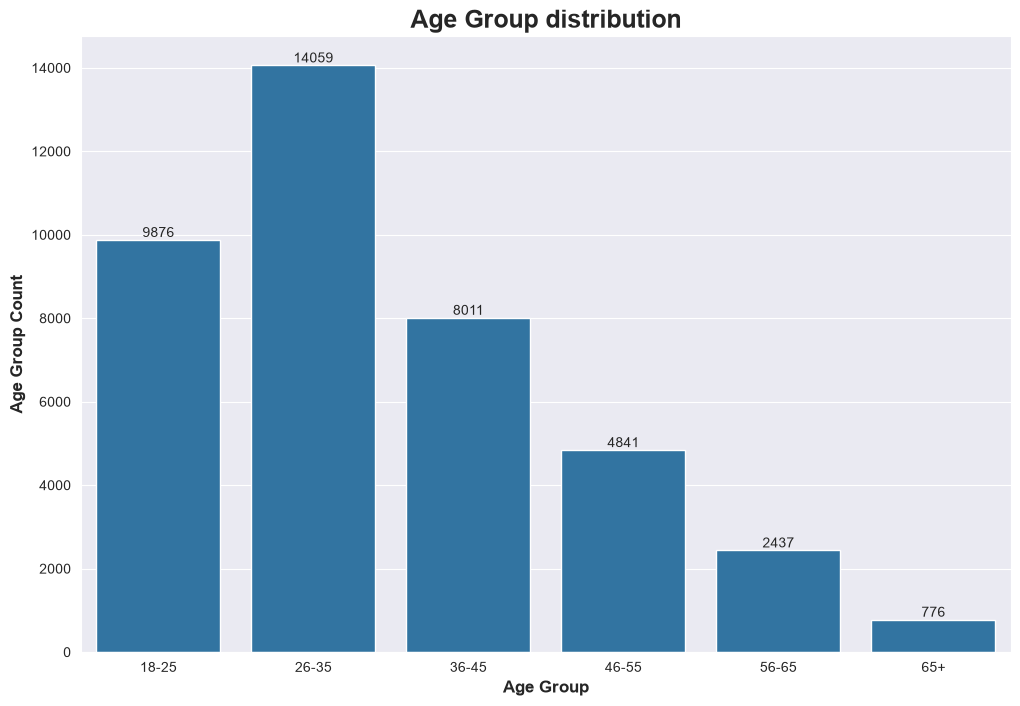

In [ ]:
plt.figure(figsize=(12,8))
sns.set_style('darkgrid')

age_order = ['18-25', '26-35', '36-45', '46-55', '56-65', '65+']

customer_df['age_group'] = pd.Categorical(customer_df['age_group'], categories=age_order, ordered=True)


ax =sns.countplot(data = customer_df, x = 'age_group')

for container in ax.containers:
    ax.bar_label(container)

ax.set_title('Age Group distribution', weight = 'bold', size = 18)
plt.xlabel('Age Group', weight = 'bold', fontsize = 12)
plt.ylabel('Age Group Count', weight = 'bold', fontsize = 12)

plt.show()

### we have customers in 18 to 35.

### City 

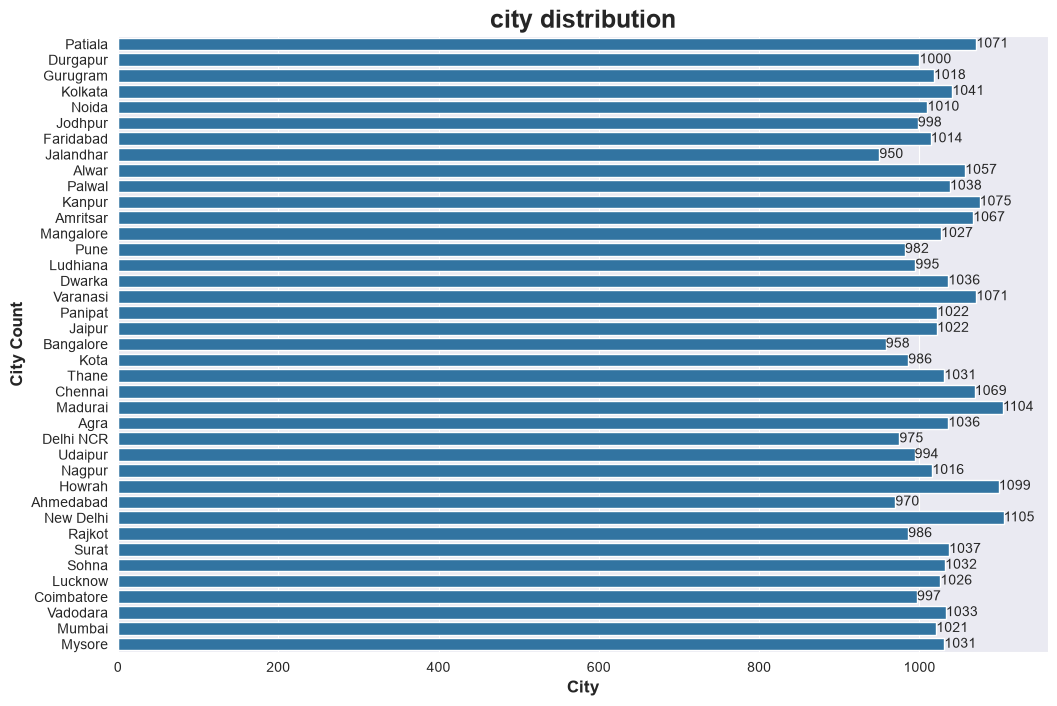

In [ ]:
plt.figure(figsize=(12,8))

ax =sns.countplot(data = customer_df, y = 'city')

for container in ax.containers:
    ax.bar_label(container)

ax.set_title('city distribution', weight = 'bold', size = 18)
plt.xlabel('City', weight = 'bold', fontsize = 12)
plt.ylabel('City Count', weight = 'bold', fontsize = 12)

plt.show()

### State

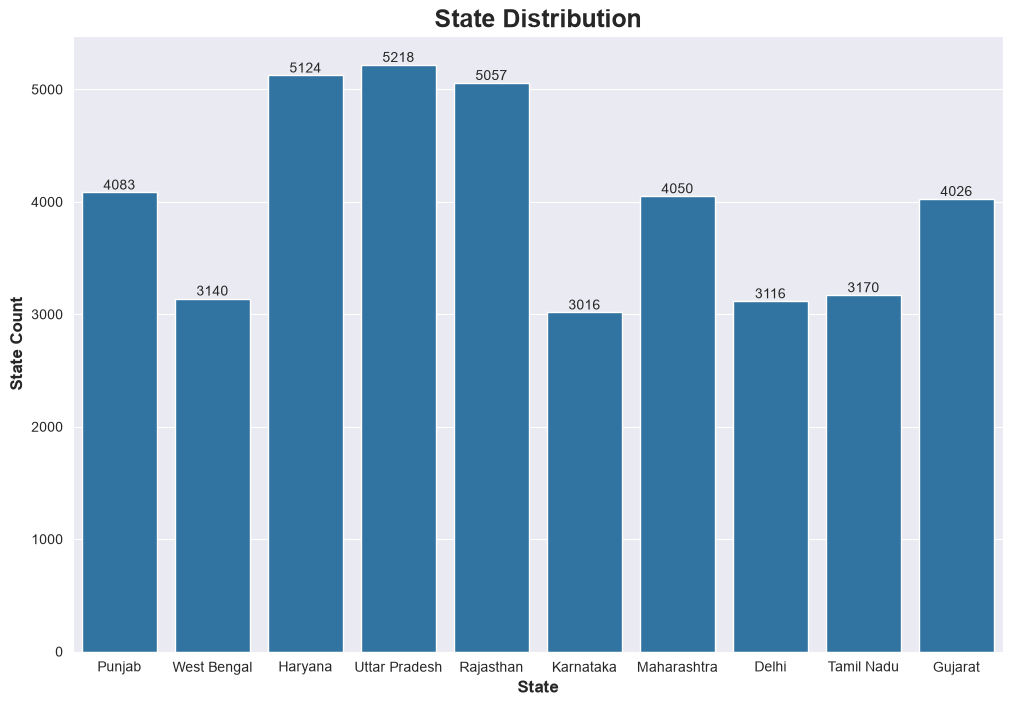

In [ ]:
plt.figure(figsize=(12,8))

ax =sns.countplot(data = customer_df, x = 'state')

for container in ax.containers:
    ax.bar_label(container)

ax.set_title('State Distribution', weight = 'bold', size = 18)
plt.xlabel('State', weight = 'bold', fontsize = 12)
plt.ylabel('State Count', weight = 'bold', fontsize = 12)

plt.show()

### Tier

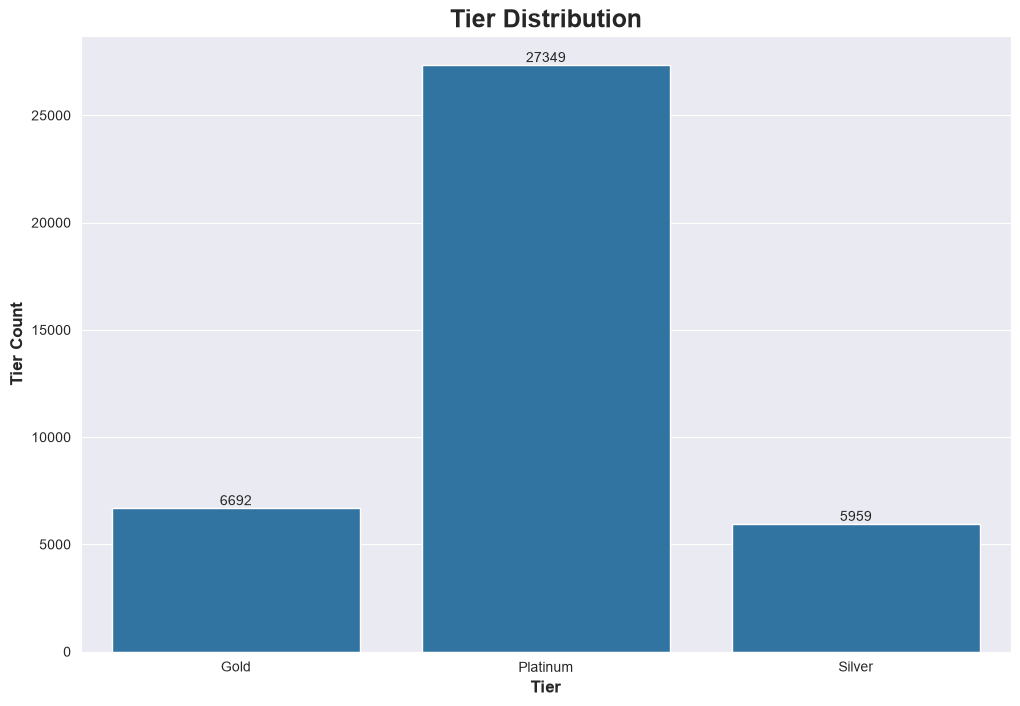

In [ ]:
plt.figure(figsize=(12,8))

ax =sns.countplot(data = customer_df, x = 'tier')

for container in ax.containers:
    ax.bar_label(container)

ax.set_title('Tier Distribution', weight = 'bold', size = 18)
plt.xlabel('Tier', weight = 'bold', fontsize = 12)
plt.ylabel('Tier Count', weight = 'bold', fontsize = 12)

plt.show()

# Products Table

### Category

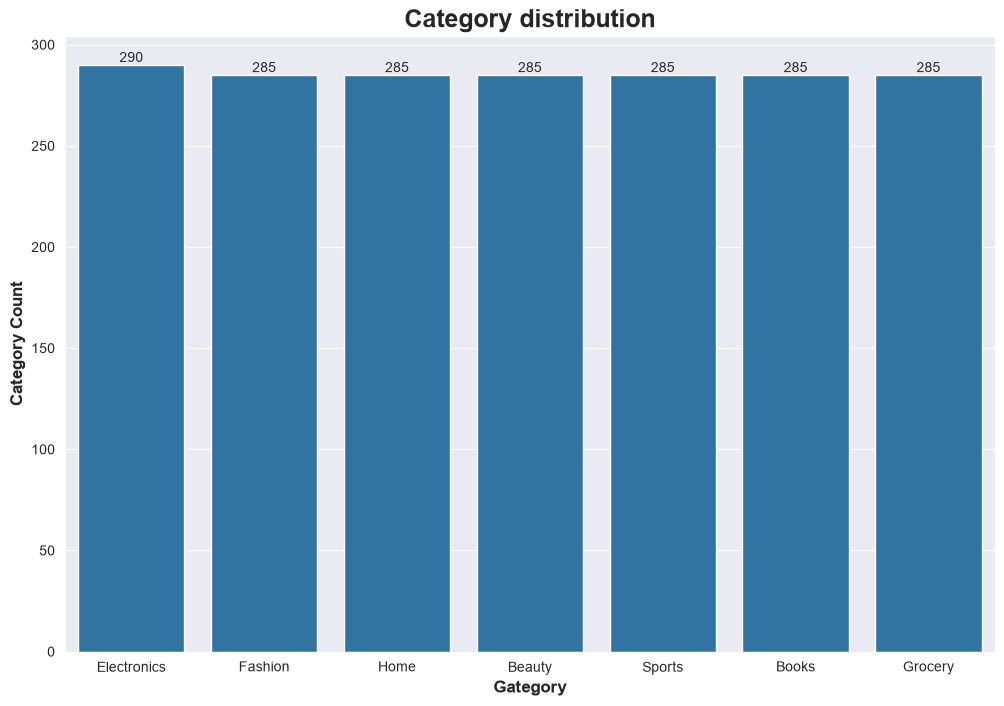

In [ ]:
plt.figure(figsize=(12,8))

ax =sns.countplot(data = product_df, x = 'category')

for container in ax.containers:
    ax.bar_label(container)

ax.set_title('Category distribution', weight = 'bold', size = 18)
plt.xlabel('Gategory', weight = 'bold', fontsize = 12)
plt.ylabel('Category Count', weight = 'bold', fontsize = 12)

plt.show()

### Brand

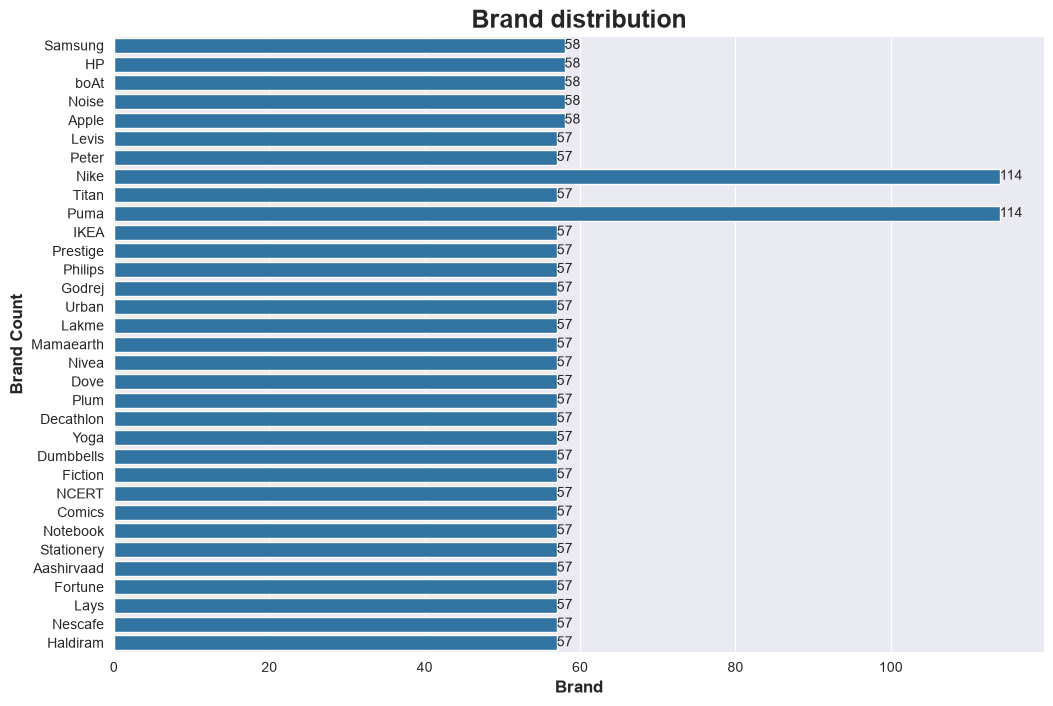

In [ ]:
plt.figure(figsize=(12,8))

ax =sns.countplot(data = product_df, y = 'brand')

for container in ax.containers:
    ax.bar_label(container)

ax.set_title('Brand distribution', weight = 'bold', size = 18)
plt.xlabel('Brand', weight = 'bold', fontsize = 12)
plt.ylabel('Brand Count', weight = 'bold', fontsize = 12)

plt.show()

# Orders Table

### Payment Mode

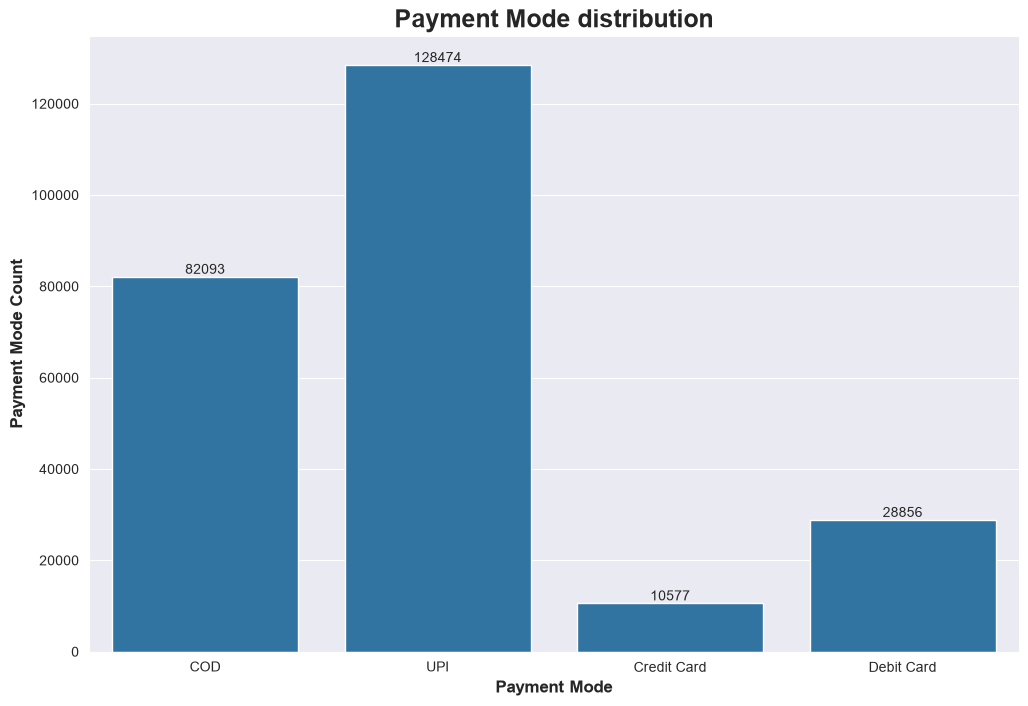

In [ ]:
plt.figure(figsize=(12,8))

ax =sns.countplot(data = orders_df, x = 'payment_mode')

for container in ax.containers:
    ax.bar_label(container)

ax.set_title('Payment Mode distribution', weight = 'bold', size = 18)
plt.xlabel('Payment Mode', weight = 'bold', fontsize = 12)
plt.ylabel('Payment Mode Count', weight = 'bold', fontsize = 12)

plt.show()

### Order Status

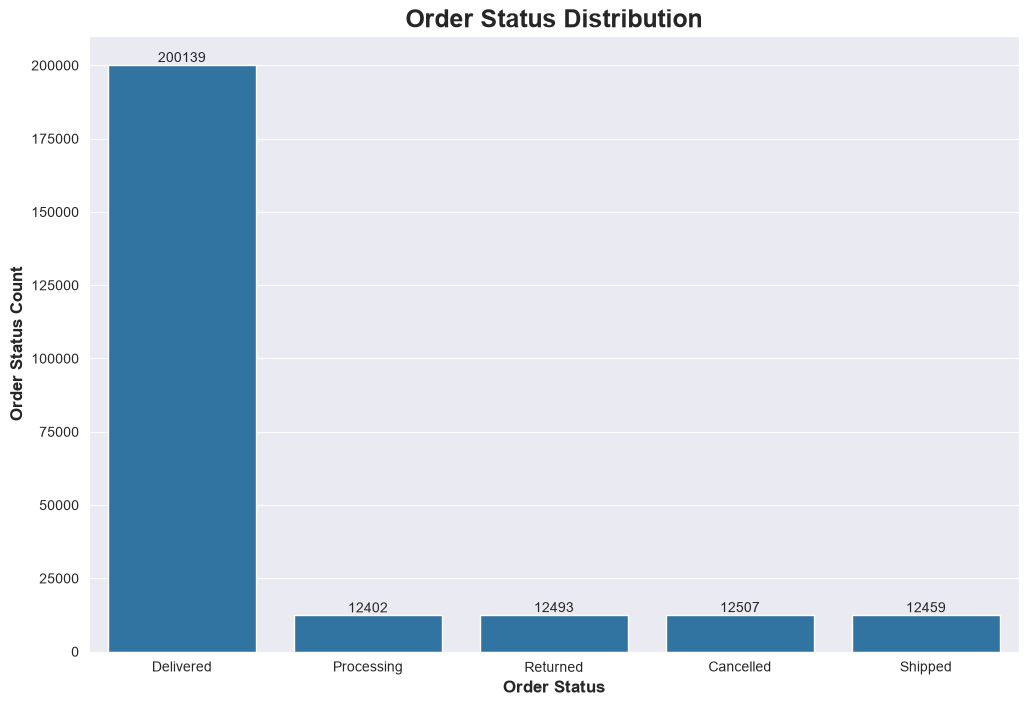

In [ ]:
plt.figure(figsize=(12,8))

ax =sns.countplot(data = orders_df, x = 'order_status')

for container in ax.containers:
    ax.bar_label(container)

ax.set_title('Order Status Distribution', weight = 'bold', size = 18)
plt.xlabel('Order Status', weight = 'bold', fontsize = 12)
plt.ylabel('Order Status Count', weight = 'bold', fontsize = 12)

plt.show()

### City

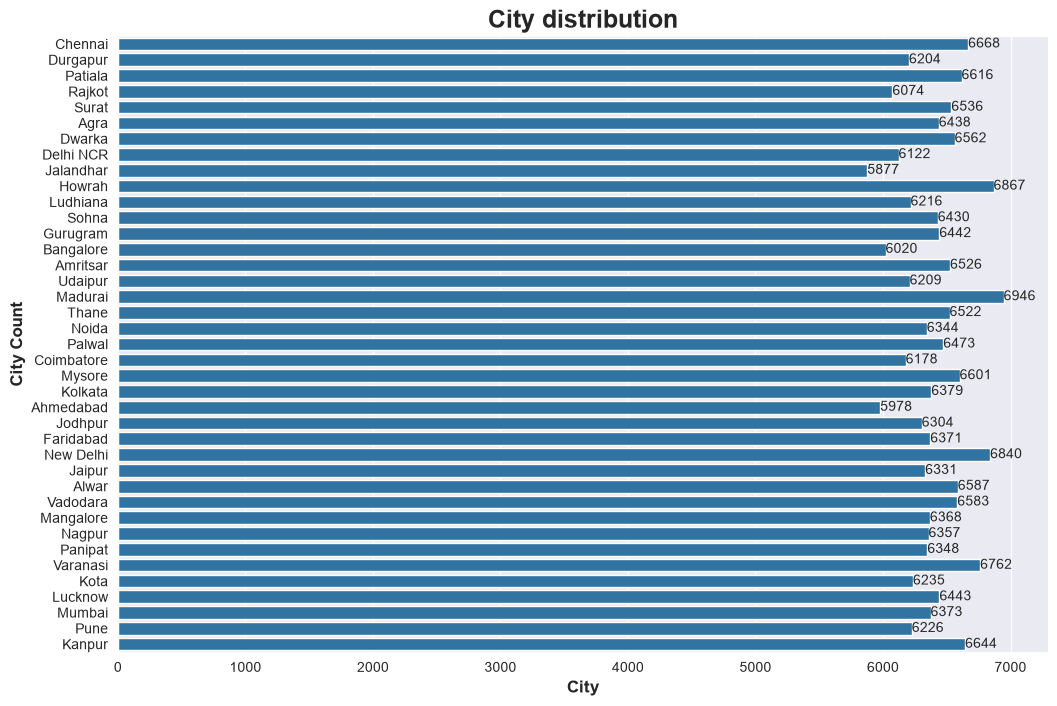

In [ ]:
plt.figure(figsize=(12,8))

ax =sns.countplot(data = orders_df, y = 'city')

for container in ax.containers:
    ax.bar_label(container)

ax.set_title('City distribution', weight = 'bold', size = 18)
plt.xlabel('City', weight = 'bold', fontsize = 12)
plt.ylabel('City Count', weight = 'bold', fontsize = 12)

plt.show()

### State

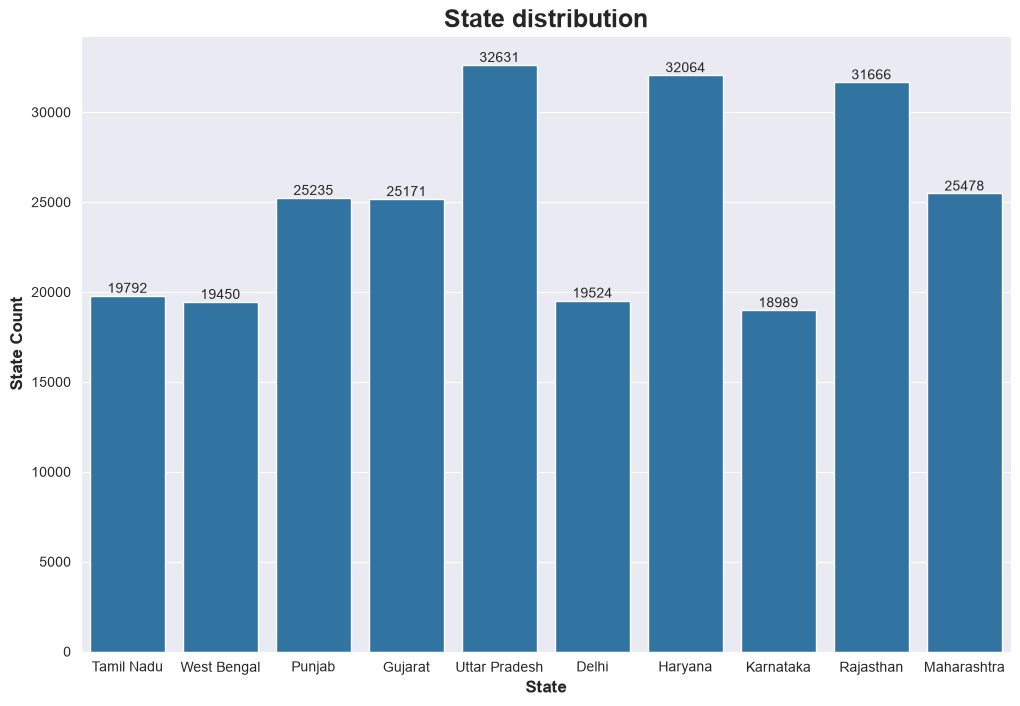

In [ ]:
plt.figure(figsize=(12,8))

ax =sns.countplot(data = orders_df, x = 'state')

for container in ax.containers:
    ax.bar_label(container)

ax.set_title('State distribution', weight = 'bold', size = 18)
plt.xlabel('State', weight = 'bold', fontsize = 12)
plt.ylabel('State Count', weight = 'bold', fontsize = 12)

plt.show()

# Numerical 

# Customer Table

### Total Orders

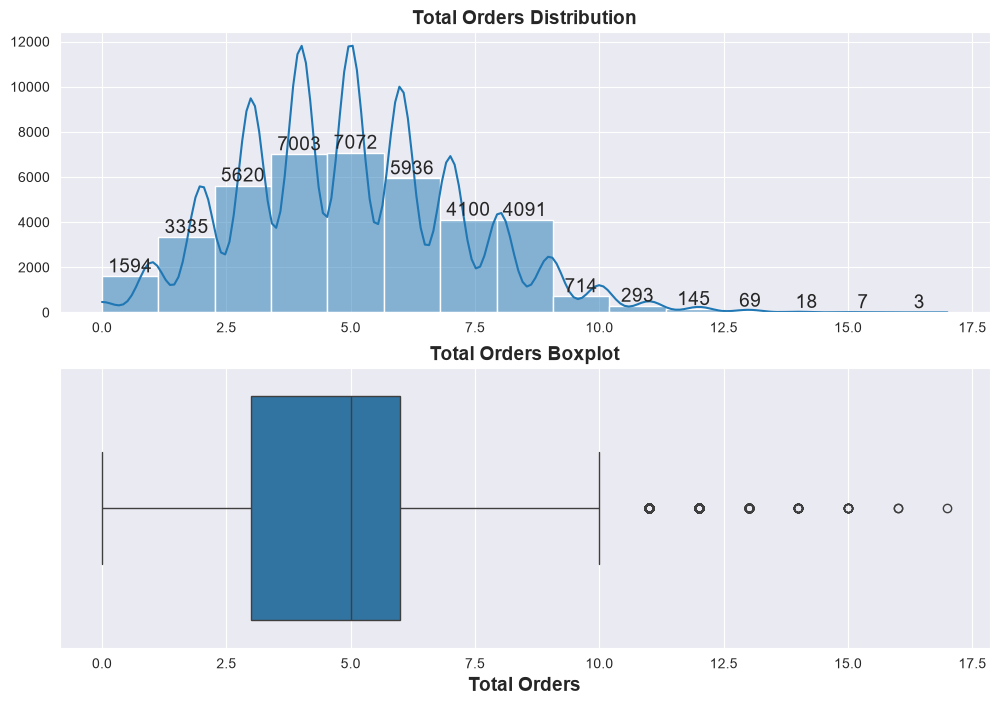

In [ ]:
plt.figure(figsize=(12,8))

plt.subplot(2,1,1)
ax = sns.histplot(data= customer_df,x = 'total_orders', bins = 15, kde= True)
for container in ax.containers:
    ax.bar_label(container, fontsize = 14)
ax.set_title('Total Orders Distribution', weight = 'bold', fontsize = 14)
ax.set_xlabel(None)
ax.set_ylabel(None)

plt.subplot(2,1,2)
ax2 = sns.boxplot(data = customer_df, x = 'total_orders')
ax2.set_xlabel('Total Orders', weight = 'bold', fontsize = 14)
ax2.set_title('Total Orders Boxplot', weight = 'bold', fontsize = 14)


plt.show()

### Total Spent

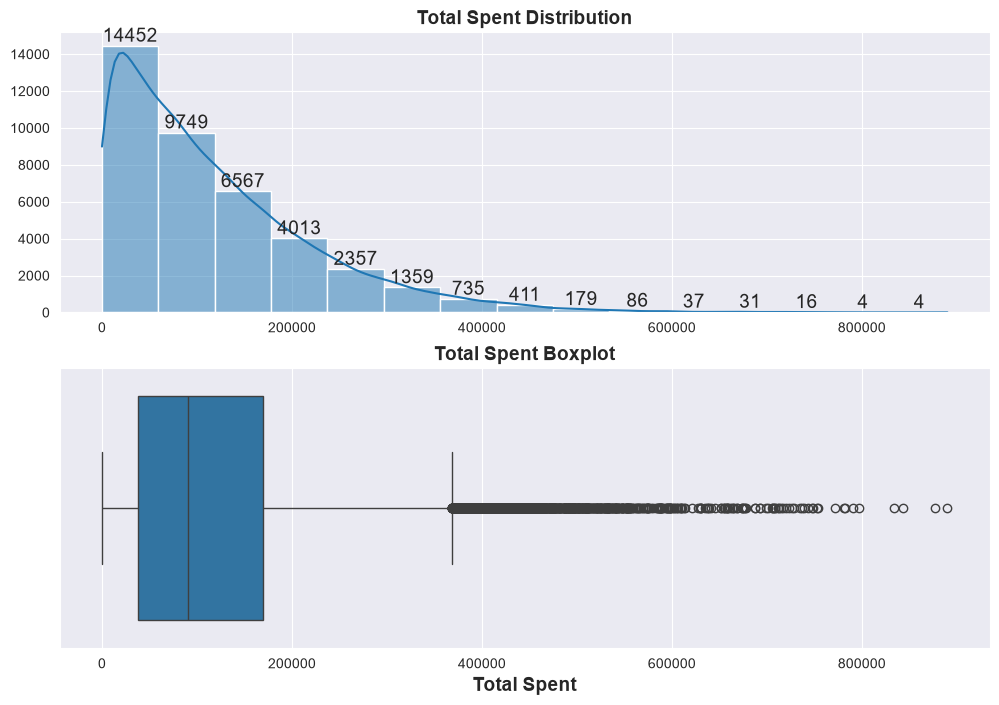

In [ ]:
plt.figure(figsize=(12,8))

plt.subplot(2,1,1)
ax = sns.histplot(data= customer_df,x = 'total_spent', bins = 15, kde= True)
for container in ax.containers:
    ax.bar_label(container, fontsize = 14)
ax.set_title('Total Spent Distribution', weight = 'bold', fontsize = 14)
ax.set_xlabel(None)
ax.set_ylabel(None)

plt.subplot(2,1,2)
ax2 = sns.boxplot(data = customer_df, x = 'total_spent')
ax2.set_xlabel('Total Spent', weight = 'bold', fontsize = 14)
ax2.set_title('Total Spent Boxplot', weight = 'bold', fontsize = 14)


plt.show()

# Product Table

### Price

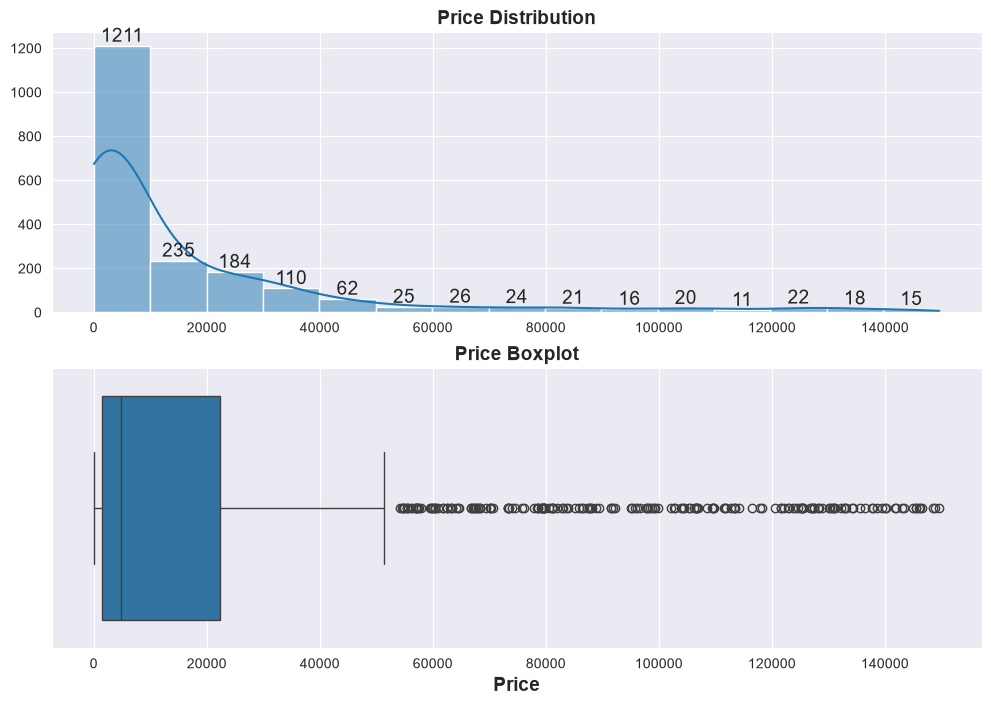

In [ ]:
plt.figure(figsize=(12,8))

plt.subplot(2,1,1)
ax = sns.histplot(data= product_df,x = 'price', bins = 15, kde= True)
for container in ax.containers:
    ax.bar_label(container, fontsize = 14)
ax.set_title('Price Distribution', weight = 'bold', fontsize = 14)
ax.set_xlabel(None)
ax.set_ylabel(None)

plt.subplot(2,1,2)
ax2 = sns.boxplot(data = product_df, x = 'price')
ax2.set_xlabel('Price', weight = 'bold', fontsize = 14)
ax2.set_title('Price Boxplot', weight = 'bold', fontsize = 14)


plt.show()

### Discount Amount

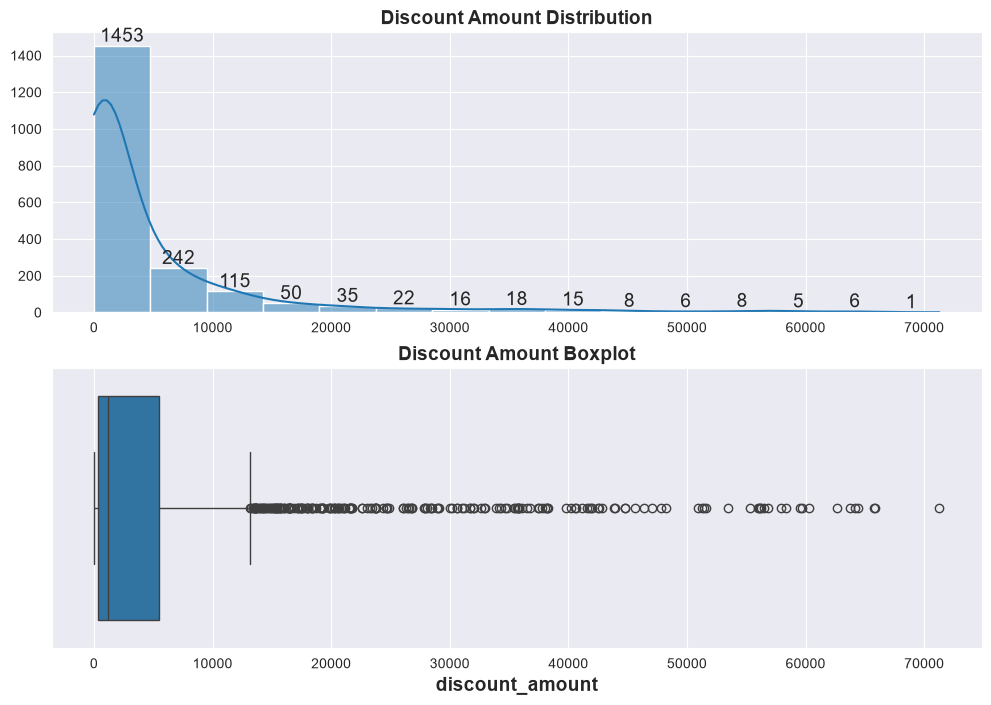

In [ ]:
plt.figure(figsize=(12,8))

plt.subplot(2,1,1)
ax = sns.histplot(data= product_df,x = 'discount_amount', bins = 15, kde= True)
for container in ax.containers:
    ax.bar_label(container, fontsize = 14)
ax.set_title('Discount Amount Distribution', weight = 'bold', fontsize = 14)
ax.set_xlabel(None)
ax.set_ylabel(None)

plt.subplot(2,1,2)
ax2 = sns.boxplot(data = product_df, x = 'discount_amount')
ax2.set_xlabel('discount_amount', weight = 'bold', fontsize = 14)
ax2.set_title('Discount Amount Boxplot', weight = 'bold', fontsize = 14)


plt.show()

### Selling Amount

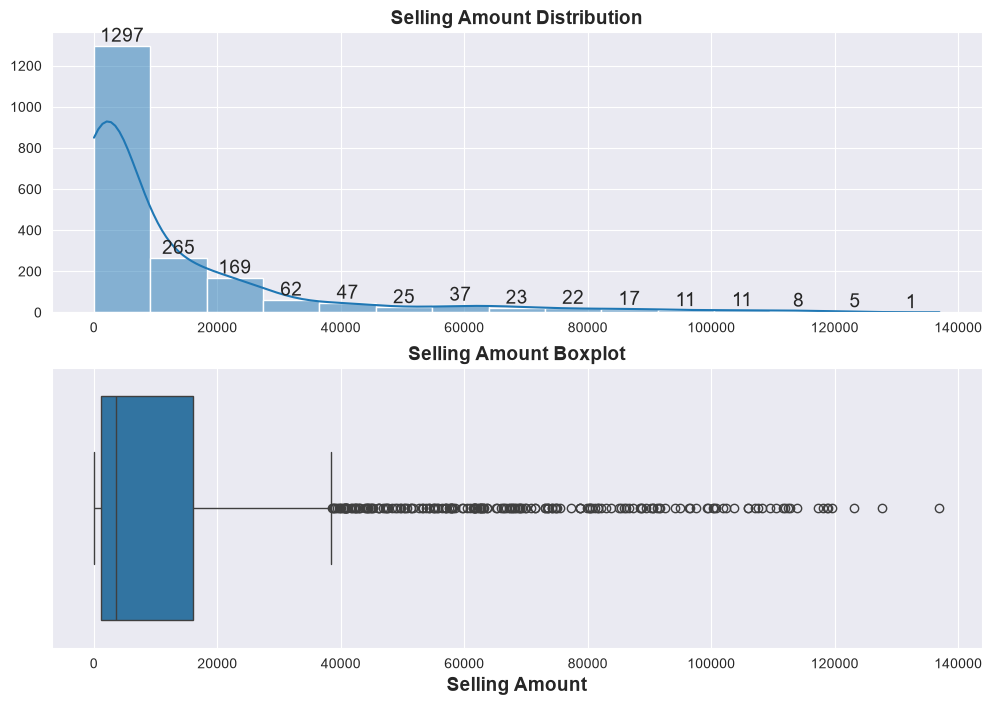

In [ ]:
plt.figure(figsize=(12,8))

plt.subplot(2,1,1)
ax = sns.histplot(data= product_df,x = 'selling_amount', bins = 15, kde= True)
for container in ax.containers:
    ax.bar_label(container, fontsize = 14)
ax.set_title('Selling Amount Distribution', weight = 'bold', fontsize = 14)
ax.set_xlabel(None)
ax.set_ylabel(None)

plt.subplot(2,1,2)
ax2 = sns.boxplot(data = product_df, x = 'selling_amount')
ax2.set_xlabel('Selling Amount', weight = 'bold', fontsize = 14)
ax2.set_title('Selling Amount Boxplot', weight = 'bold', fontsize = 14)


plt.show()

### Stock Quantity

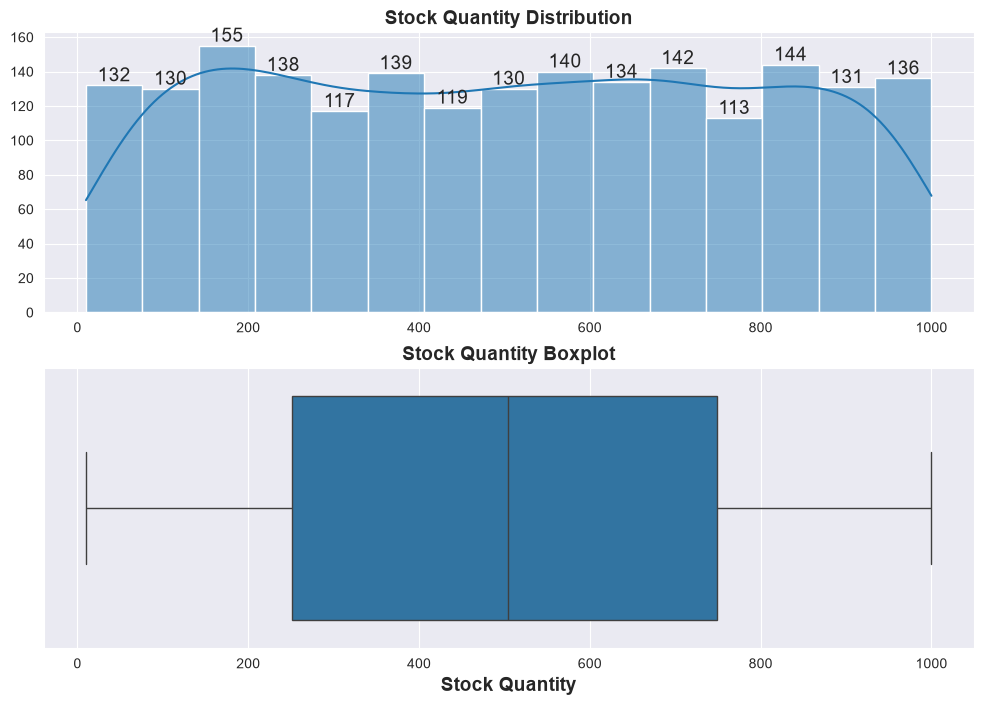

In [ ]:
plt.figure(figsize=(12,8))

plt.subplot(2,1,1)
ax = sns.histplot(data= product_df,x = 'stock_quantity', bins = 15, kde= True)
for container in ax.containers:
    ax.bar_label(container, fontsize = 14)
ax.set_title('Stock Quantity Distribution', weight = 'bold', fontsize = 14)
ax.set_xlabel(None)
ax.set_ylabel(None)

plt.subplot(2,1,2)
ax2 = sns.boxplot(data = product_df, x = 'stock_quantity')
ax2.set_xlabel('Stock Quantity', weight = 'bold', fontsize = 14)
ax2.set_title('Stock Quantity Boxplot', weight = 'bold', fontsize = 14)


plt.show()

# Orders Table

### Rating

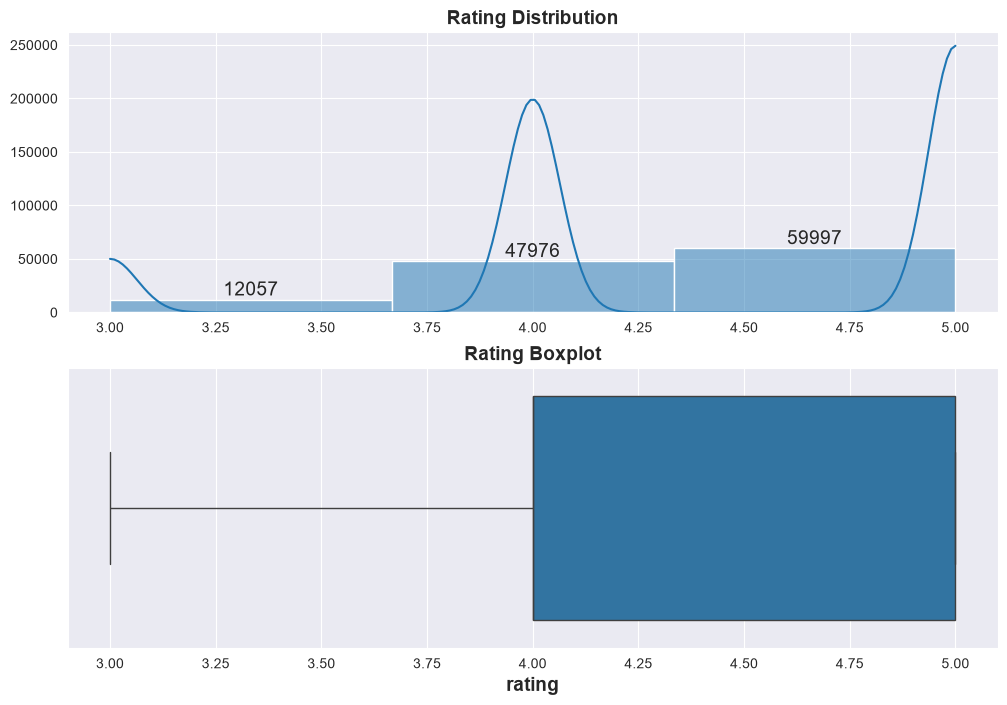

In [ ]:
plt.figure(figsize=(12,8))

plt.subplot(2,1,1)
ax = sns.histplot(data= orders_df,x = 'rating', bins = 3, kde= True)
for container in ax.containers:
    ax.bar_label(container, fontsize = 14)
ax.set_title('Rating Distribution', weight = 'bold', fontsize = 14)
ax.set_xlabel(None)
ax.set_ylabel(None)

plt.subplot(2,1,2)
ax2 = sns.boxplot(data = orders_df, x = 'rating')
ax2.set_xlabel('rating', weight = 'bold', fontsize = 14)
ax2.set_title('Rating Boxplot', weight = 'bold', fontsize = 14)


plt.show()

# Sales Table

### Quantity

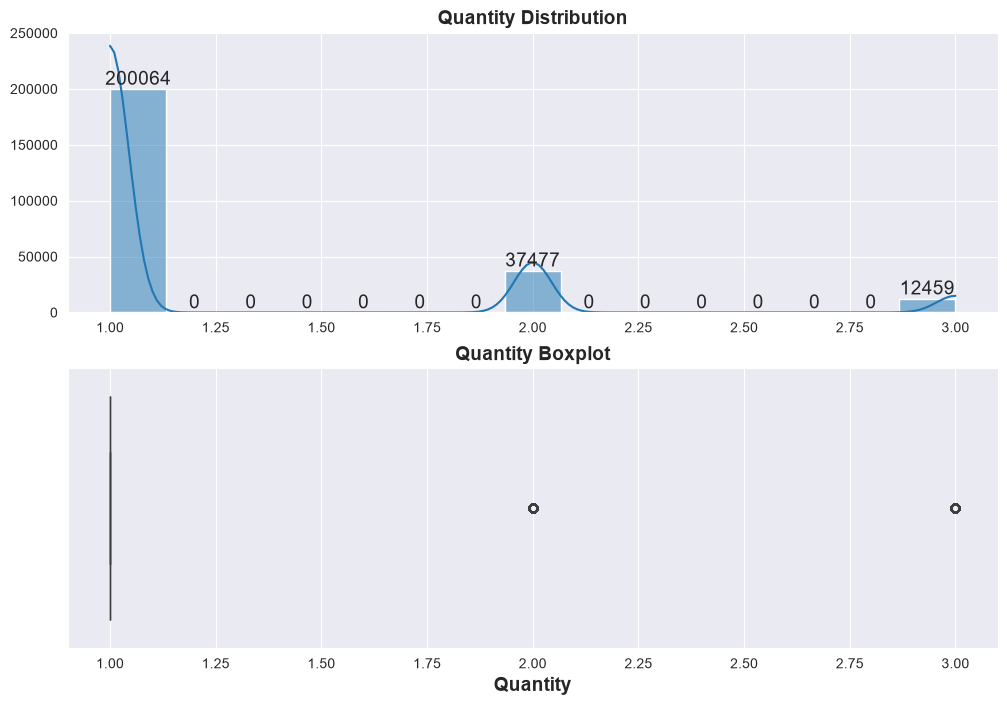

In [ ]:
plt.figure(figsize=(12,8))

plt.subplot(2,1,1)
ax = sns.histplot(data= sales_df,x = 'quantity', bins = 15, kde= True)
for container in ax.containers:
    ax.bar_label(container, fontsize = 14)
ax.set_title('Quantity Distribution', weight = 'bold', fontsize = 14)
ax.set_xlabel(None)
ax.set_ylabel(None)

plt.subplot(2,1,2)
ax2 = sns.boxplot(data = sales_df, x = 'quantity')
ax2.set_xlabel('Quantity', weight = 'bold', fontsize = 14)
ax2.set_title('Quantity Boxplot', weight = 'bold', fontsize = 14)


plt.show()

## mostly customers order quantity more than 1 are rarly orderd

### Unit Price

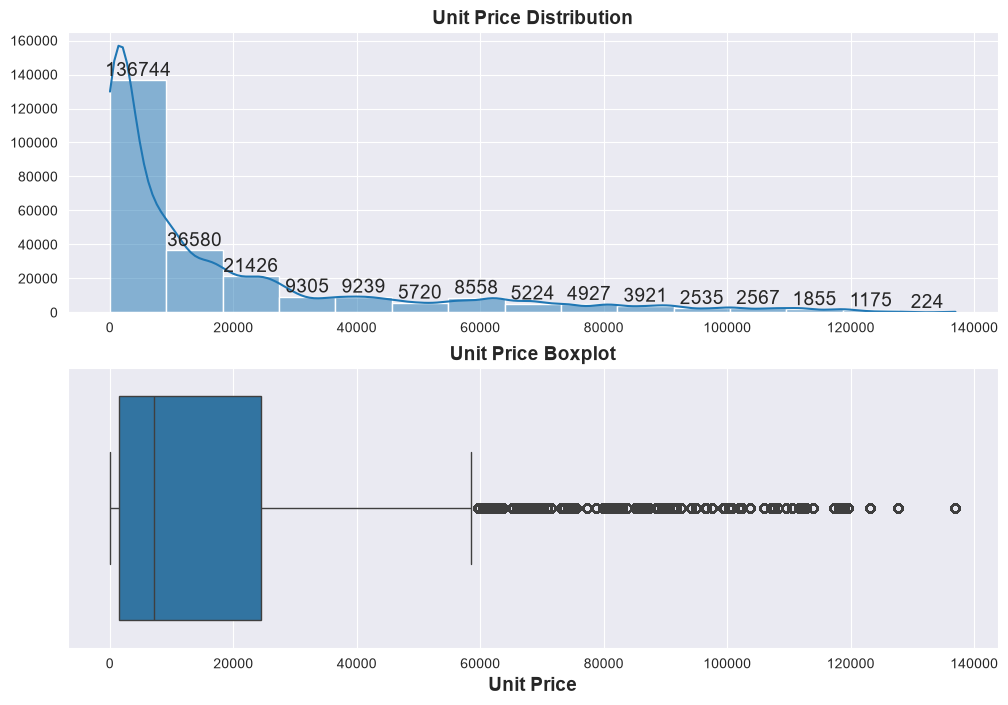

In [ ]:
plt.figure(figsize=(12,8))

plt.subplot(2,1,1)
ax = sns.histplot(data= sales_df,x = 'unit_price', bins = 15, kde= True)
for container in ax.containers:
    ax.bar_label(container, fontsize = 14)
ax.set_title('Unit Price Distribution', weight = 'bold', fontsize = 14)
ax.set_xlabel(None)
ax.set_ylabel(None)

plt.subplot(2,1,2)
ax2 = sns.boxplot(data = sales_df, x = 'unit_price')
ax2.set_xlabel('Unit Price', weight = 'bold', fontsize = 14)
ax2.set_title('Unit Price Boxplot', weight = 'bold', fontsize = 14)


plt.show()

### Order Value

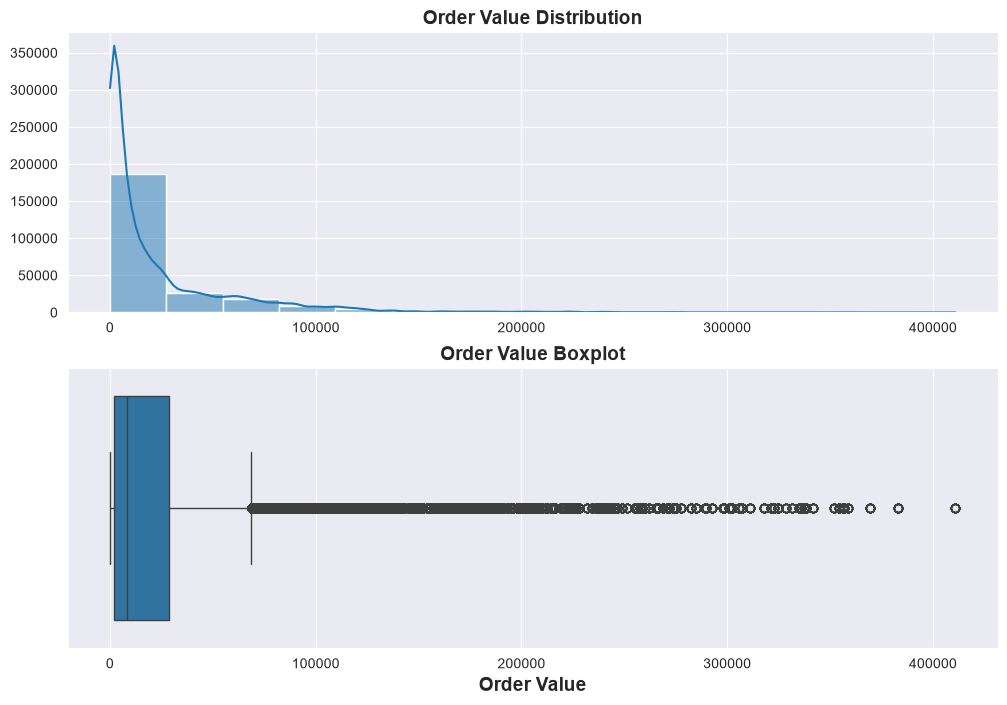

In [ ]:
plt.figure(figsize= (12,8))

plt.subplot(2,1,1)
ax = sns.histplot(data = sales_df, x = 'order_value', bins = 15, kde= True)
ax.set_title('Order Value Distribution', weight = 'bold', fontsize = 14)
ax.set_xlabel(None)
ax.set_ylabel(None)

plt.subplot(2,1,2)
ax2 = sns.boxplot(data = sales_df, x = 'order_value')
ax2.set_title('Order Value Boxplot', weight = 'bold', fontsize = 14)
ax2.set_xlabel('Order Value', weight = 'bold', fontsize = 14)

plt.show()


### Shipping Cost

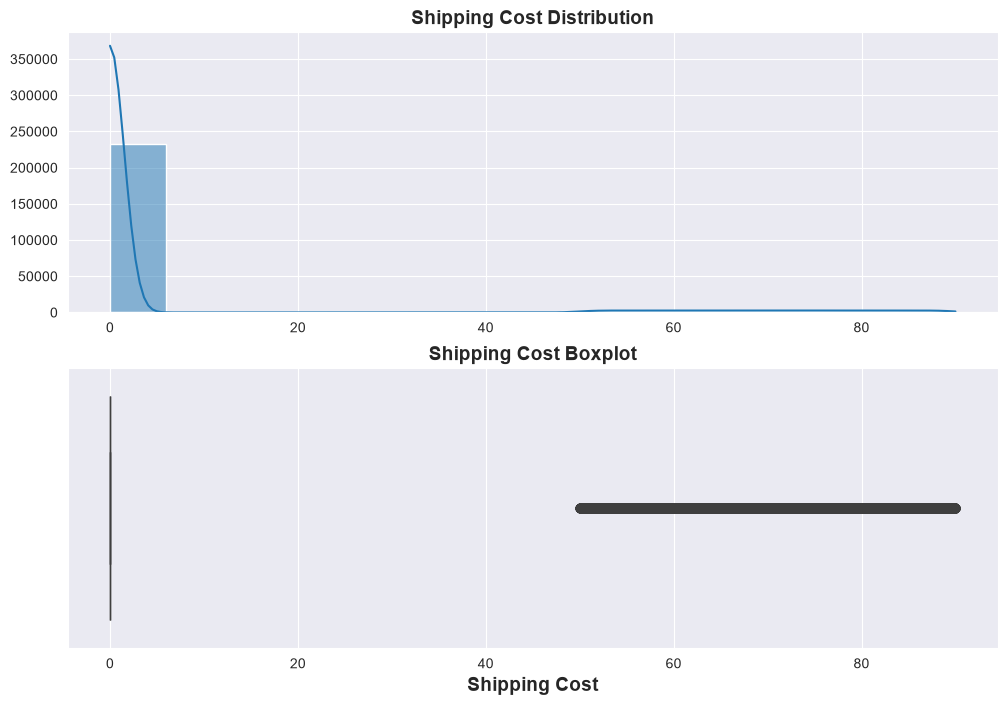

In [ ]:
plt.figure(figsize= (12,8))

plt.subplot(2,1,1)
ax = sns.histplot(data = sales_df, x = 'shipping_cost', bins = 15, kde= True)
ax.set_title('Shipping Cost Distribution', weight = 'bold', fontsize = 14)
ax.set_xlabel(None)
ax.set_ylabel(None)

plt.subplot(2,1,2)
ax2 = sns.boxplot(data = sales_df, x = 'shipping_cost')
ax2.set_title('Shipping Cost Boxplot', weight = 'bold', fontsize = 14)
ax2.set_xlabel('Shipping Cost', weight = 'bold', fontsize = 14)

plt.show()


### Coupon Discount

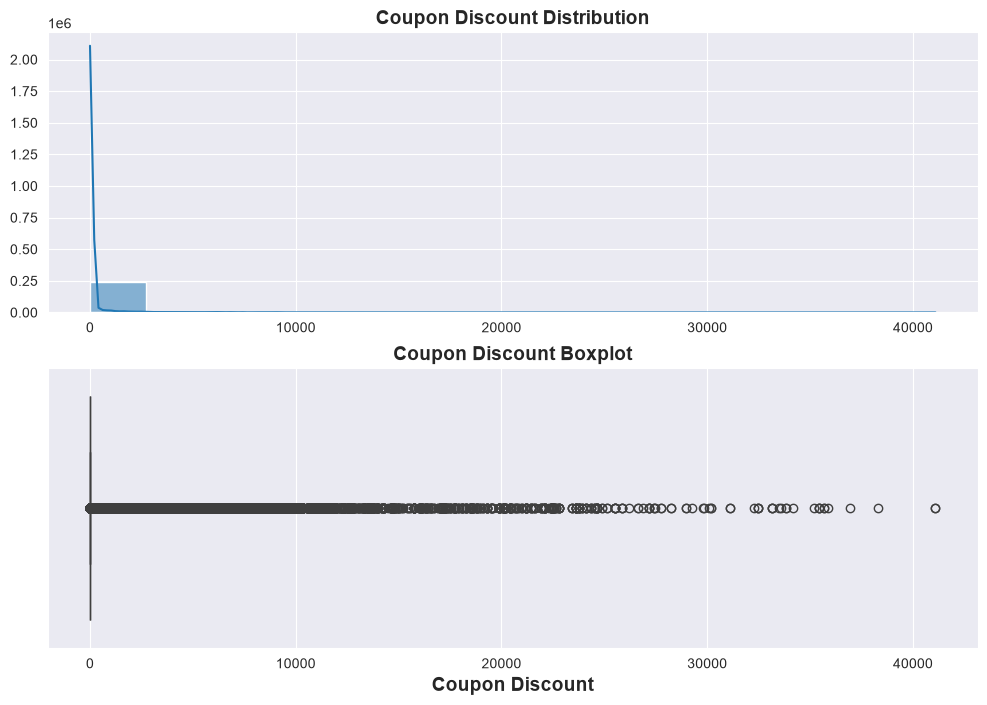

In [ ]:
plt.figure(figsize= (12,8))

plt.subplot(2,1,1)
ax = sns.histplot(data = sales_df, x = 'coupon_discount', bins = 15, kde= True)
ax.set_title('Coupon Discount Distribution', weight = 'bold', fontsize = 14)
ax.set_xlabel(None)
ax.set_ylabel(None)

plt.subplot(2,1,2)
ax2 = sns.boxplot(data = sales_df, x = 'coupon_discount')
ax2.set_title('Coupon Discount Boxplot', weight = 'bold', fontsize = 14)
ax2.set_xlabel('Coupon Discount', weight = 'bold', fontsize = 14)

plt.show()


### Total Amount

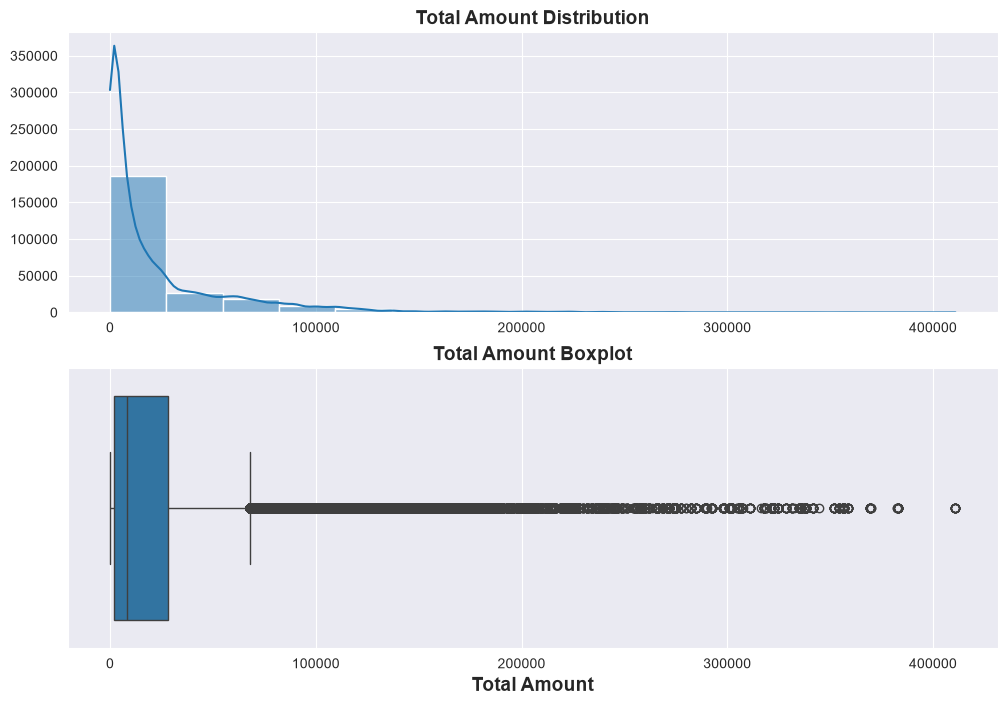

In [ ]:
plt.figure(figsize= (12,8))

plt.subplot(2,1,1)
ax = sns.histplot(data = sales_df, x = 'total_amount', bins = 15, kde= True)
ax.set_title('Total Amount Distribution', weight = 'bold', fontsize = 14)
ax.set_xlabel(None)
ax.set_ylabel(None)

plt.subplot(2,1,2)
ax2 = sns.boxplot(data = sales_df, x = 'total_amount')
ax2.set_title('Total Amount Boxplot', weight = 'bold', fontsize = 14)
ax2.set_xlabel('Total Amount', weight = 'bold', fontsize = 14)

plt.show()
